### **Student Information**
GitHub ID: ismesid

Kaggle name: ismesid02

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---
**Contents:** 1.1 Preprocessing · 1.2 Feature Engineering · 1.3 Model · 1.4 AI Prompts · 2. Results & Discussion

---

## 1. Model Development (10 pts Required)

**Describe briefly each section, you can add graphs/charts to support your explanations.**

![Score at each step, and the problem found at that step that led to the next one](pics/report_flow.png)

*Figure 1. Score at each step, and the problem found at that step that led to the next one*

#### Experiment codes used in this report

| Code | What it is |
|---|---|
| r1 | DistilRoBERTa emotion model, first fine-tune |
| r14 | `j-hartmann/emotion-english-roberta-large`, final-epoch rule, 3 seeds |
| SamLowe | `SamLowe/roberta-base-go_emotions`, 3 seeds |
| G1 / G2 / G3 | GoEmotions candidates: Epode RoBERTa-large / cirimus ModernBERT-large / fyaronskiy ModernBERT-large |
| r49 | `lzw1008/Emollama-7b` with QLoRA and its instruction format |
| S1 | r14 + SamLowe |
| S4 | r14 + SamLowe + cirimus ModernBERT-base + G3 (3 seeds each) |
| BASE | S4 + Emollama (1 seed), OOF 0.6585 |
| S9 | S4 members retrained on all 3,360 training posts (final) |
| S13 / S13′ | S9 + full-data Emollama × 2 / × 3 seeds (S13′ is final) |
| P1–P10 | preprocessing variants (Section 1.1) |
| E1 / I1 / C1 | frozen embeddings + LR / irony probability / duplicate-sentence check |
| A1 / X1 / X2 | anger–disgust specialist / + ISEAR / + GoEmotions without overlaps |


### 1.1 Preprocessing Steps｜Kept the original text.

When I first saw the hashtags, emoji, `[NAME]` placeholders, and words in ALL CAPS, my first thought was, “I should probably clean this up.” In Section 2 of the Master notebook, I’d found around 200 SemEval tweets containing a literal `\n`. Some even ended up with tokens like `😞😞\nwhy`. So I checked how many Kaggle posts had the same issue. Out of 4,800 posts, the count was zero. Even `don��t`, which looked like corrupted text, turned out to be a curly apostrophe that my terminal couldn’t display properly.

#### What was actually in the data?

Cells 8–10 of the Homework notebook showed 4,800 posts in total, with 3,360 in the training set and 1,440 in the test set. There were no missing values, duplicate IDs, or blank posts. The IDs were all unique, but some posts had exactly the same text.

| What I checked | What I found |
|---|---|
| Class distribution | The training set had 875 joy examples, 674 anger, 628 sadness, 454 disgust, 441 surprise, and 288 fear. |
| Duplicate text | The training set had 50 groups of posts with identical text. Labels conflicted in 16 groups, so only 68% of the groups had consistent labels. Another 59 test posts exactly matched text in the training set. |
| Text features | Of all 4,800 posts, 347 contained `[NAME]` (7.2%), 136 contained `@<username>`, and 31 contained `##URL##`. I also found 72 posts with hashtags, 159 with emoji, 322 with curly quotes, and 636 with an all-caps word at least three letters long. |
| Post length | The median was 13 words, and 95% of posts were 32 words or shorter. The longest one had 510 words. After tokenization, only about 0.8% of posts were truncated at `max_len = 128`. |

There were over three times as many joy examples as fear examples, but the competition used macro F1, so the two classes carried the same weight. For the full experiments, I used stratified 5-fold cross-validation to keep the class proportions similar across folds. Two copies of the same post could still end up on opposite sides of a split. Seeing the same text during training and validation could make the out-of-fold (OOF) scores a little optimistic.

Later in the competition, on November 20, I compared the posts with GoEmotions using only the text. After lowercasing and collapsing repeated whitespace, I found exact matches for about 44% of the training posts and 45% of the test posts (see Section 2).

#### Which changes were worth trying?

With TF-IDF, I wanted to combine different ways of writing the same word because tokenization and lowercasing affect which features the vectorizer builds. With a pretrained transformer, I was less sure. The model had already seen text from the web, and I was asking it to recognize emotion. Someone writing `WHY` in all caps or adding a few extra *o*s to `sooo` might be doing it for a reason. Drop `not` from `not happy` during stopword removal and the meaning flips.

I had two other idea on my list. P2 was to remove the `#` from hashtags like `#fuming`, and P3 was to turn emoji into English descriptions. Across the whole dataset, only 72 posts had hashtags and 159 had emoji. I figured it would be hard to see much difference in the overall macro F1, so I put those two further down the list.

For the experiments I ran, I used the original text as the baseline and changed one thing at a time. To save training time, I tried each idea with a **quick setup** (3 folds, `max_len = 64`, 3 epochs). With that same setup, the original text scored **0.6303, 0.6353, and 0.6308** across three seeds, with a mean of **0.6321**.

| Experiment | What I changed | Quick-run macro F1 | What I decided |
|---|---|---:|---|
| P1 | Replaced curly quotes with straight quotes so that `don’t` and `don't` would be written the same way. | 0.6275 | It scored below all three baseline runs, so I kept the original quotes. |
| P4 | Within the training portion of each fold, removed examples that had identical text but conflicting labels. | 0.6282 | This removed only 8–16 examples per fold. The score was below all three baseline runs, so I kept those examples. |
| P10 | Replaced `[NAME]` with an English name, using the same replacement each time the same post appeared. | 0.6329 | A little above the mean, but still within the baseline range of 0.6303–0.6353. I kept `[NAME]`. |

![Preprocessing changes vs. seed noise on the original text](./pics/report_preprocessing.png)

*Figure 2. Preprocessing changes vs. seed noise on the original text*

P4 needed a fix before I even ran it. My original plan was to scan the entire training set for conflicting labels and then split it into folds. The third review caught a leak in that plan. Say a post was labeled anger in the training portion and an identical post was labeled disgust in validation. I would’ve dropped the training example, but how would I have known there was a conflict? I’d have to look at the validation label. So in the actual run, I split the data first and checked for conflicts only within the training portion of each fold. The **0.6282** in the table comes from that corrected version.

For P5, I could check the predictions I already had. Each of the 59 test posts that matched training text had just one corresponding label in the training set. I considered using that label directly, then checked what my best ensemble at the time (S4, see Section 1.3) had predicted. For **57 of the 59 posts (96.6%)**, its prediction already matched the training label. Adding the rule would only change two predictions, so I didn’t end up use it.

The final `prepare_text()` just returns the original text. Only the TF-IDF baseline lowercases it, inside the vectorizer. P10 scored **0.0008** above the baseline mean, but the baseline itself varied by **0.0050** just from changing the seed. I’d already used those three baseline runs to confirm the 0.005 threshold in Section 1.3 before I tried P10. With a gain that small, I couldn’t tell whether replacing the names had helped.

---

### 1.2 Feature Engineering Steps

#### Starting with TF-IDF

For Round 0, I went with something I knew from class. I combined word 1–2 grams with `char_wb` 2–5 grams, which gave me 35,032 TF-IDF features. I trained on 85% of the data and kept 15% as a holdout. On that split, Logistic Regression (`C=5`, `class_weight="balanced"`) scored 0.5465 macro F1, ahead of LinearSVC at 0.5298. I kept Logistic Regression as my baseline. Its Kaggle public score was 0.5045.

Disgust had the lowest holdout F1 at **0.394**. If someone uses a bunch of negative words in a post, even I’d have trouble telling from those words alone whether they’re angry or genuinely disgusted. That gave me a reason to try a model that could use the wording of the whole sentence.

#### Switching to DistilRoBERTa

For Round 1, I picked a DistilRoBERTa model that had already been trained on English emotion classification. Its labels were pretty close to ours. I fed the original text from Section 1.1 straight into its tokenizer. With TF-IDF, I’d chosen the n-gram features up front. During fine-tuning, the model could use our emotion labels to adjust how it represented each post.

DistilRoBERTa scored **0.6206** on 5-fold OOF. On Kaggle, my public score went from 0.5045 to 0.6163. The public and OOF scores were only 0.0043 apart on this run, which gave me a reason to keep using OOF for the next comparisons.

I report two local scores for TF-IDF. The 0.5465 came from that first 15% holdout. When I reran TF-IDF on the same five folds as the transformers, its OOF score was **0.4977**. I used that second score in E1.

#### E1: How much would frozen sentence embeddings help?

Switching to DistilRoBERTa changed two things in one go. I’d started using a pretrained model, and I’d fine-tuned it on the competition labels. In E1, I tried taking sentence embeddings off the shelf and putting Logistic Regression on top, the same classifier I’d used with TF-IDF.

I used `sentence-transformers/all-mpnet-base-v2` as the main encoder and tried `sentence-transformers/all-MiniLM-L6-v2` as a second check. Both encoders stayed frozen. Only Logistic Regression was trained on the competition data.

| Method | 5-fold OOF macro F1 |
|---|---:|
| TF-IDF + Logistic Regression | 0.4977 |
| Frozen `all-mpnet-base-v2` + Logistic Regression | 0.4929 |
| Frozen `all-MiniLM-L6-v2` + Logistic Regression | 0.5043 |
| Fine-tuned `bertweet-large` (no GoEmotions training) | 0.6055 |
| Fine-tuned Emollama (no GoEmotions training) | 0.6181 |

One frozen encoder landed just below TF-IDF and the other just above it. I also checked whether the result for MPNet depended on my choice of `C`. With its embeddings, `C=0.1` gave 0.4956, and pushing `C` up to 10 dropped the score to 0.4673.

My guess is that two posts can be close in meaning but still need different emotion labels. Someone saying something sincerely and someone saying it sarcastically might use almost the same words. A general-purpose encoder trained for semantic similarity could lose some of that difference in tone. In these runs, switching from n-grams to frozen embeddings left the score around 0.50. The two models fine-tuned without GoEmotions reached 0.6055 and 0.6181.

The `j-hartmann` model (r14) reached 0.6262 when I scored each seed separately and averaged the three scores. It had also trained on GoEmotions, so given the text overlap in Section 2, I wouldn’t give fine-tuning all the credit for that extra gain. Disgust still had the lowest F1 across the methods I compared.

#### Adding training data to SamLowe

I tried giving SamLowe more data in two ways. First, I used masked language modeling (MLM) to replace words in the training posts. Then I tried pseudo-labeling test posts and keeping the predictions with the highest confidence.

For both experiments, I averaged the final-epoch OOF probabilities across three seeds before calculating macro F1, which gave 0.6251 for the original SamLowe. I estimated that seed variation could still move the difference between two such runs by about 0.006, so before training I set the minimum gain at 0.008.

**MLM augmentation.** I kept 2,655 of the 3,360 candidate sentences, about 79%. Adding those sentences and training three seeds took SamLowe from 0.6251 to 0.6259 (+0.0008). My guess is that SamLowe had already seen plenty of similar wording during pretraining, so the replacements gave it little else to learn.

**Pseudo-labels.** The S2 ensemble labeled the test posts by averaging predictions from four teachers: r14, SamLowe, cirimus-b, and G3. For each fold, I used only the four teachers trained for that fold. SamLowe was also the model I retrained, so it was partly learning from its own predictions.

With a confidence cutoff of 0.8, each fold added 661–688 of the 1,440 test posts, about 46–48%. I checked the same cutoff on the labeled training set using OOF predictions. There, 47.6% of posts passed, and accuracy on those posts was 0.884. Even among the confident OOF predictions, roughly 12% were wrong. The retrained SamLowe reached 0.6277. The gain of **+0.0026** was larger than the one I got from MLM, but still short of the 0.008 cutoff.

#### Adding signals to the ensemble

For the last two experiments, I used the existing model probabilities. My baseline, `BASE`, combined the four models in S4 with Emollama and scored 0.6585 OOF.

**Irony probability.** I took `p_irony` from `cardiffnlp/twitter-roberta-base-irony` and used it to adjust the class probabilities from `BASE`. The idea was to give the ensemble an explicit signal about the tone of each post. For this experiment, I required an OOF gain of at least 0.005 and a confidence interval with a lower bound above zero.

Higher irony probability pushed joy down and surprise up, which was the direction I’d expected. The average change in macro F1 was +0.0000. Shuffling `p_irony` across posts gave −0.0003, and both confidence intervals included zero. I left the feature out.

**Giving TF-IDF a 5% weight.** Codex suggested bringing TF-IDF back as a small ensemble member. It used different features from the transformers, so even with an OOF score around 0.50, it might still catch a few posts they missed. Giving it a 5% weight took `BASE` from 0.6585 to 0.6563 (**−0.0022**).

Those 5% changed the predicted class on 28 OOF posts. When the top two classes were close, that small weight could switch the answer, and most of those switches were mistakes. I kept TF-IDF as the baseline for E1 and used the fine-tuned transformer ensemble for the final predictions.

![OOF results for MLM augmentation, pseudo-labels, irony probability, and the 5% TF-IDF blend](pics/report_tried_ideas.png)

*Figure 3. OOF results for MLM augmentation, pseudo-labels, irony probability, and the 5% TF-IDF blend*

---

### 1.3 Explanation of Your Model

#### Seed variation and the 0.005 cutoff

I split the 3,360 training posts into five stratified folds. Each time, I trained on four folds and predicted the fifth. After five rounds, every post had one prediction from a model that hadn’t trained on it. I calculated macro F1 over all 3,360 out-of-fold (OOF) predictions. I fixed `split_seed=42` so each post stayed in the same fold across experiments. When I repeated a run, I changed `train_seed`, which affected model initialization and the order of the training data.

I changed one thing at a time and set a default cutoff of 0.005 for deciding whether an OOF gain was large enough to keep. Later, I checked that rule by running the same quick baseline (r7) with three training seeds. The scores were 0.6303, 0.6353, and 0.6308, with a mean of 0.6321 and a spread of exactly 0.0050. The spread stayed within the cutoff I’d already set, so I kept the rule for the comparisons described in Section 1.1. I used the public leaderboard to check whether the score moved in the same direction, but made keep-or-drop decisions locally.

In the early RoBERTa-large run, I picked the best epoch on each validation fold and reported its score on that same fold, which made the 0.6343 OOF score optimistic. For the later baseline, I used the final epoch in every fold and averaged probabilities across three seeds, giving an OOF score of 0.6279.

#### Switching from DistilRoBERTa to RoBERTa-large

I first tried changing how I trained the DistilRoBERTa model from Section 1.2. Class weighting brought OOF down to 0.6171. Label smoothing brought it up to 0.6220, a gain of 0.0014. Switching to `j-hartmann/emotion-english-roberta-large` brought the early OOF score up to 0.6343, a gain of 0.0137 over the original small model.

I got the model from Hugging Face. Jochen Hartmann had trained it on several English emotion datasets, including GoEmotions and SemEval-2018. Six of its seven output classes matched ours, so I kept the output weights it had already learned for those six classes, dropped neutral, and continued fine-tuning on the competition posts.

I’d also changed the learning rate along the way, so I went back to the quick runs to see how much credit it deserved. At the same learning rate of `1e-5` and seed 42, the small model scored 0.6174 and the large model scored 0.6303, a gap of 0.0129. Changing just the learning rate on the small model gave +0.0014. Most of the improvement came from switching models.

#### Building S4, one member at a time

In my initial comparison, averaging runs of the same model with different seeds gave me +0.0017. Averaging r14 with SamLowe gave about +0.017, roughly ten times as much. Both had trained on GoEmotions, but they differed in size and training data. They seemed to make different enough mistakes that averaging their predictions helped.

I gave each model equal weight. If a model had several seeds, I averaged its seed probabilities first, so training an extra seed wouldn’t give that model a bigger vote. I ranked new candidates by their individual OOF scores, tried them in that order, and kept a candidate if it improved the current ensemble by at least 0.005.

For models already in the ensemble, I’d decided to use all three planned seeds. S1, the r14–SamLowe ensemble, scored 0.6449 with two SamLowe seeds and 0.6428 with three. Keeping the two-seed version because it happened to score higher would have meant picking the seed count after seeing the result. I used 0.6428 as the starting point for the next round.

| Candidate, in the order I tried it | Individual OOF | OOF with candidate | Change from current ensemble | Decision |
|---|---:|---:|---:|---|
| G1, Epode RoBERTa-large | 0.6301 | 0.6462 | +0.0034 | Skip |
| cirimus ModernBERT-base | 0.6249 | 0.6483 | +0.0055 | Add |
| G2, cirimus ModernBERT-large | 0.6247 | 0.6500 | +0.0017 | Skip |
| G3, fyaronskiy ModernBERT-large | 0.6124 | 0.6536 | +0.0053 | Add |
| bhadresh BERT-base | 0.5755 | 0.6532 | −0.0004 | Skip |

G1 had the highest individual score and still missed the cutoff. It shared the RoBERTa-large architecture and GoEmotions training with r14, so overlapping errors were one plausible explanation. G3 ranked fourth out of five on its own, yet it added 0.0053 even after ModernBERT-base had joined. I tried all five candidates on the same OOF predictions, though, so the score after selection could be a little optimistic.

Once I’d completed three seeds for each of the four members, I called the ensemble **S4**. This is the combination I used for the duplicate-post check in Section 1.1.

| S4 member | Hugging Face model | 5-fold OOF after averaging three seeds |
|---|---|---:|
| r14 | `j-hartmann/emotion-english-roberta-large` | 0.6279 |
| SamLowe | `SamLowe/roberta-base-go_emotions` | 0.6251 |
| cirimus-b | `cirimus/modernbert-base-go-emotions` | 0.6267 |
| G3 | `fyaronskiy/ModernBERT-large-english-go-emotions` | 0.6138 |
| S4 | Equal average of the four members | 0.6537 |

With all seeds in place, removing cirimus-b cost 0.0043, and removing G3 cost 0.0042. Both drops were smaller than the gains I’d seen when first adding them. I also checked class-specific offsets, Logistic Regression stacking, geometric averaging, and a weight search. The best weight combination, `(2, 2, 1, 1)`, gained only about 0.001 in nested evaluation. I kept the equal average.

![OOF scores as models were added to the ensemble](pics/report_ensemble.png)

*Figure 4. OOF scores as models were added to the ensemble*

#### Training models with a fresh output head

Since switching to RoBERTa-large had worked, I tried larger models that hadn’t already learned emotion classification. Each started with a fresh output head. DeBERTa-v3-large scored 0.5648 across all five folds. I screened the other three on fold 0: ModernBERT-large scored 0.561, Qwen2.5-0.5B with full fine-tuning scored 0.5609, and Qwen2.5-7B with QLoRA scored 0.5424.

ModernBERT’s training loss got all the way down to 0.02, and its fold 0 score was still stuck around 0.56. By then it could fit the training posts almost perfectly. Giving Qwen more parameters didn’t get me past 0.56 either. The 7B run actually finished below the 0.5B run, although the difference in fine-tuning methods makes it hard to isolate the effect of size.

I didn’t finish two runs from my original plan. I skipped the 10-epoch DeBERTa run because another five folds would take about two GPU hours, and at 0.5648 OOF I didn’t expect a few more epochs to make it useful for S4. The Qwen2.5-3B LoRA run hit an environment error before training started, and I didn’t rerun it.

The decoder that got past the screen was `lzw1008/Emollama-7b` (r49), a LLaMA model that had already trained on emotion tasks. With its instruction format, it scored 0.6164 on fold 0, about 0.074 above the 7B Qwen run. I’d also tried giving Emollama the plain post text in r48, but the loss went to `NaN`. Without a working plain-text run, I couldn’t measure the effects of the model and its instruction format seperately.

Across five folds, Emollama scored 0.6181 with one seed and 0.6282 after averaging three. I then gave it the same weight as each of S4’s four members.

| Ensemble | 5-fold OOF macro F1 | Gain over S4 |
|---|---:|---:|
| S4 | 0.6537 | — |
| S4 + Emollama, one seed | 0.6585 | +0.0048 |
| S4 + Emollama, two seeds | 0.6595 | +0.0058 |
| S4 + Emollama, three seeds | **0.6598** | +0.0061 |

The one-seed blend is the 0.6585 `BASE` from Section 1.2. It missed the cutoff by 0.0002. With two seeds, the gain cleared the cutoff, although its 95% confidence interval still included zero [−0.0004, +0.0120]. I calculated that interval only for the two-seed blend. When the third seed was ready, I used the completed average, which brought OOF to 0.6598.

I also checked which posts accounted for the gain. On the 139-post tweet subset, adding one Emollama seed lowered the score from 0.4619 to 0.4428. On the non-tweet posts, it rose from 0.6601 to 0.6650. The gain showed up outside the tweet subset, which gave me little support for the idea that prior exposure to SemEval tweets explained it. I tried adding a second decoder from the same family, Emollama-chat-7b. It agreed with r49 on about 80% of predictions, and adding it cost 0.0046.

![Model experiments from the initial baseline through Emollama](pics/report_model_path.png)

*Figure 5. Model experiments from the initial baseline through Emollama*

#### Final submissions: S13′ and S9

For S9, I retrained S4’s four members with three seeds each, using all 3,360 training posts. Each of the 12 runs saw 25% more training data than it had in a single cross-validation fold. Since I’d used every post for training, I had no OOF score for S9. Before retraining, I wrote down three checks to flag a full-data run that behaved very differently from S4.

| Full-data check | Requirement | Result |
|---|---|---|
| Agreement with S4’s test predictions | At least 92% | 97.43% |
| Predicted count for each class | Within ±15% of S4 | Largest difference was 1.5% |
| Final-epoch training loss | Within the planned ±30% tolerance | Largest difference was 2.4% |

For S13′, I also trained Emollama on all 3,360 posts with three seeds. I averaged the probabilities from those seeds and combined them with S9 as `(4 × S9 + Emollama) / 5`. That gave each of the five models the same weight it had in the OOF ensemble.

The two submissions I was considering were too similar. I wanted one final slot for a version without Emollama in case the decoder’s OOF gain didn’t carry over to private, so I kept S9 for that slot. For the other, I’d decided in advance to replace S13 with S13′ if the full-data version passed all its checks. It passed, so my final pair was S13′ and S9.

---

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

- I set the one-change-per-round rule and turned down Claude’s first GPU script because it bundled three configurations into one run and produced three CSVs.
- The MLM augmentation, irony feature, and anger/disgust specialist were ideas I brought to Claude, and I asked it to try larger models too.
- When Claude ruled out LoRA on Kaggle, I asked why. It turned out the restriction applied to my local environment.
- I also pointed out that my two proposed final submissions were too similar and settled on S13′ and S9 after the second Codex review.

I used Claude Code to write and run the competition code, submit GPU jobs through the Kaggle CLI, and maintain the experiment log. The prompts below are summaries of what I asked.

#### Stage 1: Setting up the baseline and GPU runs

**TF-IDF baseline.** I asked Claude to compare LinearSVC and Logistic Regression with TF-IDF on the same validation split. I knew the method from class, understood what the features represented, and could run both classifiers quickly. I kept Logistic Regression after the holdout comparison (see Section 1.2).

**GPU fine-tuning.** I asked Claude to revise the training script so I could trace each output file to a single change. If I was testing a larger model, the learning rate should stay fixed. Testing the learning rate would take a separate run.

**Kaggle CLI.** Claude suggested submitting jobs from my computer through the Kaggle CLI and downloading the results afterward. I had an OJ exam coming up, so I used it to keep training jobs running without having to stay on the Kaggle page.

#### Stage 2: Running and reviewing experiments

On November 19, I asked Claude Code to keep the planned experiments running while I prepared for and took my OJ exam. After r4–r6, I decided that each new plan and its code should be checked before training. I asked a second Claude session to look for two things in particular: whether validation data could affect training, and whether I’d changed more than one thing in a run. I used OOF to decide which changes to keep and the public score to check whether they moved in the same direction.

When the reviewer looked back at r4, it pointed out that I’d changed the model size and the learning rate together. I’d broken my own rule there. To work out which change accounted for the gain, I asked Claude to compare the two model sizes at the same learning rate, then compare learning rates on the small model (see Section 1.3).

The third review caught the validation-label leak in my P4 plan before I ran it (see Section 1.1).

I questioned Claude’s interpretation of r14 as well. It said the model started overfitting after the first epoch, but that claim came from seed 42. I checked the other seeds, and the pattern didn’t hold up, so I dropped it from the report.

#### Stage 3: My experiments and the suggestions I reviewed

| My idea → what Claude implemented | Why I tried it and what I decided |
|---|---|
| **MLM augmentation (S3).** Generate alternative training sentences by masking and replacing words, then retrain SamLowe. | I wanted to give the model more ways to express a similar emotion. I compared the run with the original SamLowe using the cutoff set beforehand and kept the original data (see Section 1.2). |
| **Irony probability (I1).** Add `p_irony` from an existing irony model and test a shuffled version as a control. | I wanted to check whether an explicit signal about tone added anything to the ensemble. The OOF comparison gave me little reason to keep it (see Section 1.2). |
| **Anger/disgust specialist (A1).** Train a model specifically to distinguish anger from disgust, then test its predictions alongside the main ensemble. | I chose these two labels because disgust was the hardest class and many of its errors went to anger. The specialist results are in Section 2.4. |
| **Larger decoders.** Try Qwen 3B and 7B, then try Emollama with its instruction format. | The 3B run stopped before training because of an environment error, and the 7B run fell short. I tried Emollama next because it had already trained on emotion tasks. Its blend cleared the cutoff after I added more seeds (see Section 1.3). |

On November 20, I asked Codex (GPT-6.2-Astra) for two read-only reviews of the project files. I asked it to look for comparisons I’d missed and review my proposed final submissions. I also tested suggestions from the independent Claude reviewer.

| Review suggestion | What I did with it |
|---|---|
| Use different ensemble weights depending on whether a post matched GoEmotions. | I skipped this. The weighting rule was unclear, and we’d already seen the subgroup scores. I’d be using the same OOF posts to invent the rule and judge it. |
| Check whether duplicate sentences accounted for r49’s gain (C1). | I accepted this suggestion from the first Codex review because I’d already found duplicate text in Section 1.1. The gain remained after the duplicate check. |
| Try class-specific offsets, Logistic Regression stacking, and a weight search. | I tested them with nested cross-validation. None improved enough on the equal average to justify changing the weights (see Section 1.3). |
| Stop starting new experiments after S15 and finalize the submissions. | I accepted the second Codex review’s recommendation and selected S13′ and S9 (see Section 1.3). |

#### Preparing the Homework notebook and report

**Notebook.** I asked Claude to move the competition code into the Homework notebook, run the CPU steps, and include a compact version of the GPU training code. I rebuilt S13′ from the saved probabilities and compared the output with the CSV I’d submitted. They matched exactly. I rewrote the notebook comments myself.

**Figures.** I asked AI to generate the figures from the notebook outputs and experiment log. I checked the plotted values against the corresponding runs before including them.

**Report text.** I wrote my experiment notes and reasoning in Chinese, then used ChatGPT to organize them into sections, draft the English version, and revise the wording with me. One draft said SamLowe had labeled the test posts on its own. The score in that paragraph was right, so checking the number alone would’ve missed the error. I went back to the pseudo-labeling log and corrected the description. All four S2 models supplied the teacher predictions, and SamLowe was both one of those teachers and the model I retrained.

---

## 2. Results & Discussion

### 2.1 Final results

I finished 1st on the public leaderboard and **9th out of 103 teams on private**, in the top 9%. My two final submissions were S13′ and S9. Kaggle took the higher of their private scores, so my final macro F1 was **0.6629** from S13′.

| Submission | What went into it | Local macro F1 | Public | Private |
|---|---|---:|---:|---:|
| Baseline | TF-IDF + Logistic Regression | 0.5465 (15% holdout) | 0.5045 | 0.4908 |
| r1 | DistilRoBERTa emotion model | 0.6206 | 0.6163 | 0.6100 |
| S1 | r14 × 3 seeds + SamLowe × 3 seeds | 0.6428 | 0.6345 | 0.6516 |
| S4 | Four-model ensemble | 0.6537 | 0.6556 | 0.6541 |
| S4+r49 | S4 + Emollama, averaged across five folds | 0.6585 | 0.6717 | **0.6663** |
| S14A | S4 + Emollama × 2 seeds, averaged across five folds | 0.6595 | 0.6717 | 0.6653 |
| S9 (final) | S4 members retrained on all training posts | — | 0.6699 | 0.6602 |
| S13 | S9 + full-data Emollama × 2 seeds | — | **0.6778** | 0.6591 |
| S13′ (final) | S9 + full-data Emollama × 3 seeds | — | 0.6722 | 0.6629 |

The local scores are 5-fold OOF macro F1 except for the baseline’s original holdout score. The three full-data submissions have no OOF score because every training post was used to fit the models.

My highest private score was 0.6663 from S4+r49, one of the files I didn’t select. That put my final submission 0.0034 behind my best one. I can’t tell how many posts accounted for that gap from the scores alone, since the effect of each changed prediction depends on the classes involved.

![Public and private macro F1 for each submission, sorted by public score](pics/report_leaderboard.png)

*Figure 6. Public and private macro F1 for each submission, sorted by public score*

### 2.2 What changed when the private scores came out

Going from 1st to 9th did sting a little. S13 had my highest public score, 0.6778, but its private score of 0.6591 was the lowest among the five later variants in the table. Public favored S13 over S13′ by 0.0056, while private favored S13′ by 0.0038. Before the deadline, I’d estimated public-score noise at around ±0.018. If I’d switched back to S13 because of its public score, I would’ve picked the weaker of the two on private.

OOF tracked the larger changes fairly well. The private scores followed the same order as OOF from r1 to S1 to S4 to S4+r49: 0.6100, 0.6516, 0.6541, and 0.6663. The size of the gains was less predictable. Moving from S1 to S4 gained 0.0109 locally, but only 0.0025 on private. I’d still use OOF to make those decisions again. I’d just be more careful about expecting a local gain to carry over at the same size.

Both five-fold Emollama blends scored higher on private than all three full-data versions. I’d picked the full-data versions partly because each model got to train on 25% more posts. One possible advantage of the five-fold setup is that it averaged predictions from models trained on slightly different data. Retraining on all 3,360 posts gave up that source of variation, and I had no OOF score for the retrained versions to check what I’d gained in return.

Knowing the private scores now, I would’ve kept S4+r49. At the time, I couldn’t see the 0.0034 advantage that would give it over S13′. The gaps were only a few thousandths, so I don’t have much evidence that full-data retraining helped here. One private split is also too little to say that five-fold averaging will always win.

### 2.3 GoEmotions overlap and what it means for the scores

As described in Section 1.1, I found exact text matches in GoEmotions for 44% of the competition training set and 45% of the test set after normalizing case and whitespace. That included **644 test posts**. I used only the text for the overlap check. For X2, the experiment where I trained a specialist with external GoEmotions examples, I first removed the 405 sentences in its candidate pool that matched any of the 4,800 competition posts.

The harder part to account for was training that happened before I downloaded the models. All four members of S4 had already trained on GoEmotions. Depending on which examples they had seen, they may have encountered some of those 644 test posts together with their original GoEmotions labels. The TA later confirmed that fine-tuning Hugging Face models and using public emotion datasets were allowed. My email asked about those uses in general. I hadn’t specifically asked about the test-text overlap, so the reply didn’t address that particular case.

To see how much the overlap might matter, I split the labeled competition training posts into two groups and calculated macro F1 from their existing OOF predictions. This let me compare performance on matching and non-matching posts without using any test labels.

| Model | Prior GoEmotions training | Matching posts | Non-matching posts | Gap |
|---|---|---:|---:|---:|
| S4 | Yes, all four members | 0.778 | 0.537 | +0.241 |
| Emollama | No | 0.683 | 0.556 | +0.127 |
| BERTweet | No | 0.679 | 0.535 | +0.144 |

Even Emollama and BERTweet scored about 0.13–0.14 higher on matching posts. That subset seems easier for models without GoEmotions training too. For individual models that had trained on GoEmotions, the gap was around 0.21–0.23, roughly another 0.08–0.10 in many of the comparisons. The models also differ in architecture, training data, and overall ability, so I can’t tell how much of that extra gap came from prior exposure alone.

I also tried three ensembles using models that hadn’t trained on GoEmotions. I started with Emollama and BERTweet, added CardiffNLP, then added DeBERTa. On non-matching posts, the three ensembles scored between 0.555 and 0.557, all above S4’s 0.537. Across the full training set, they scored 0.6267, 0.6287, and 0.6307, respectively, while S4 scored 0.6537. This suggests that much of S4’s overall lead came from the posts that matched GoEmotions.

Emollama raises a similar question about possible prior exposure to labeled SemEval tweets. Tweets made up about 4% of the training set. On the fold 0 tweet subset, Emollama scored about 0.40 versus 0.51 for S4, but that comparison covered **only 32 posts**. I couldn’t verify exactly which examples Emollama had seen, and a subset that small tells me little about prior exposure. For those 32 posts, at least, Emollama showed no advantage over S4.

### 2.4 The errors I still couldn’t fix

Disgust was already the weakest class in my first baseline, and it was still the weakest by recall in the final OOF analysis. Its **recall was 0.443**. Of the 454 disgust posts, 123 were predicted as anger, about 27%. The next largest confusion was surprise → joy, with 77 posts. Seeing how often disgust ended up as anger was why I spent time on a specialist for those two classes, even after the overall score had improved quite a bit.

![OOF confusion matrix showing 123 disgust posts predicted as anger and 77 surprise posts predicted as joy](pics/report_confusion.png)

*Figure 7. OOF confusion matrix showing 123 disgust posts predicted as anger and 77 surprise posts predicted as joy*

The A1 specialist reached 0.7137 accuracy on the anger/disgust comparison, below the ensemble’s 0.7491. Adding it to the ensemble lowered overall OOF macro F1 by 0.0037. I then tried giving the specialist external data. For these follow-up runs, I screened on fold 0 and used the ensemble’s anger/disgust accuracy on that fold, **0.7699**, as the target.

| Specialist experiment | Extra training data | Fold 0 anger/disgust accuracy |
|---|---|---:|
| X1 | 2,132 ISEAR sentences | 0.7212 |
| X2 | 1,490 GoEmotions sentences after removing overlaps | 0.7345 |

On fold 0, the A1 specialist alone had an anger/disgust accuracy of 0.7212. Adding ISEAR gave exactly the same score. Adding the filtered GoEmotions examples raised it to 0.7345, just three more correct predictions. Both specialists still fell short of the ensemble’s 0.7699 on that fold.

My guess is that part of the difficulty is in the labels themselves. Section 1.1 found 16 groups where identical text had conflicting emotion labels. Those groups don’t tell me how many anger/disgust errors were ambiguous, but they make me cautious about assuming that another batch of labeled sentences would settle the distinction.

If I ran the competition again, I’d check the training sources of the pretrained models as soon as I had a baseline. I found the GoEmotions overlap on November 20, after I’d already made several model choices. Finding it earlier would have let me build an ensemble without GoEmotions training sooner and track its OOF score on non-matching posts alongside the overall score.

I’d also reserve one final slot for a five-fold average, since both submissions I selected this time used full-data retraining (see Section 1.3).

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

**how this section is organised**

- the default run takes a few seconds on cpu. it loads and checks the competition data, rebuilds the tf-idf baseline, and puts the final ensemble back together from the saved probabilities.
- we fine-tuned the transformers on kaggle with 2× T4 gpus. the training code is in section 3.2, but it's off here (`RUN_GPU_TRAINING = False`) since one 7B model takes about 2.5 gpu-hours per seed. section 3.3 loads the saved 5-fold out-of-fold and test probabilities.
- the competition files and saved probabilities are kept **outside this public repository** (`../kaggle_data/` and `../kaggle_work/runs/`). the competition data stays in those local folders.

## 1. Preprocessing Steps

In [1]:
# ---- 1.1 Join the post text, split assignments, and training labels ----
from pathlib import Path
import json, re
import numpy as np
import pandas as pd

DATA = Path("../kaggle_data")          # final_posts.json, data_identification.csv, emotion.csv (outside the repo)
RUNS = Path("../kaggle_work/runs")     # probabilities saved by the Kaggle GPU runs (outside the repo)
SUBS = Path("../kaggle_work/submissions")
LABELS = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]   # fixed class order used everywhere
L2I = {l: i for i, l in enumerate(LABELS)}

posts = pd.DataFrame(json.load(open(DATA / "final_posts.json", encoding="utf-8")))   # post_id, text
ident = pd.read_csv(DATA / "data_identification.csv")                                  # post_id, set (train/test)
labels = pd.read_csv(DATA / "emotion.csv")                                             # post_id, label (train only)

df = posts.merge(ident, on="post_id")
train = df[df.set == "train"].merge(labels, on="post_id").reset_index(drop=True)
test = df[df.set == "test"].reset_index(drop=True)
y = train.label.map(L2I).values        # integer labels in LABELS order

print("posts", posts.shape, "| train", train.shape, "| test", test.shape)
print(train.label.value_counts().to_string())

posts (4800, 2) | train (3360, 4) | test (1440, 3)
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288


In [2]:
# ---- 1.2 Check the data as loaded ----
print("missing values :", int(df.isna().sum().sum()))
print("duplicate ids  :", int(df.post_id.duplicated().sum()))
print("empty texts    :", int((df.text.str.strip() == "").sum()))

# Group identical training posts and check whether their labels differ.
dup_groups = train.groupby("text").label.agg(["size", "nunique"])
dup_groups = dup_groups[dup_groups["size"] > 1]
print(f"train texts that appear more than once: {len(dup_groups)} groups, "
      f"{int(dup_groups['nunique'].gt(1).sum())} of them with conflicting labels")

# Check for exact matches across splits that could leak test examples into training.
overlap = set(train.text) & set(test.text)
print("texts shared by train and test:", len(overlap))

missing values : 0
duplicate ids  : 0
empty texts    : 0
train texts that appear more than once: 50 groups, 16 of them with conflicting labels
texts shared by train and test: 59


In [3]:
# ---- 1.3 Count text patterns and summarize post lengths ----
emoji_re = re.compile("[\U0001F300-\U0001FAFF☀-➿]")
checks = {
    "[NAME] placeholder (GoEmotions style)": df.text.str.contains(r"\[NAME\]", regex=True),
    "@<username> placeholder": df.text.str.contains("@<username>", regex=False),
    "##URL## placeholder": df.text.str.contains("##URL##", regex=False),
    "hashtag (#word)": df.text.str.contains(r"#\w", regex=True),
    "emoji": df.text.map(lambda t: bool(emoji_re.search(t))),
    "literal backslash-n": df.text.str.contains("\\n", regex=False),
    "curly quotes": df.text.str.contains("[‘’“”]", regex=True),
}
print(pd.DataFrame({"posts": {k: int(v.sum()) for k, v in checks.items()},
                    "share": {k: round(float(v.mean()), 3) for k, v in checks.items()}}).to_string())

n_words = df.text.str.split().str.len()
print("\nwords per post: median", int(n_words.median()), "| 95th pct", int(n_words.quantile(.95)),
      "| max", int(n_words.max()))

                                       posts  share
[NAME] placeholder (GoEmotions style)    347  0.072
@<username> placeholder                  136  0.028
##URL## placeholder                       31  0.006
hashtag (#word)                           72  0.015
emoji                                    159  0.033
literal backslash-n                        0  0.000
curly quotes                             322  0.067

words per post: median 13 | 95th pct 32 | max 510


In [4]:
# ---- 1.4 Preprocessing for the final models ----
# The TF-IDF baseline only lowercases text inside TfidfVectorizer.
# Words like "not", punctuation like "!", and emoji can all give clues about emotion.
# Each transformer gets the original text and uses its own tokenizer.
# We tested each option on Kaggle: normalizing curly quotes, replacing [NAME]
# with random names, dropping duplicates with conflicting labels, MLM augmentation,
# and pseudo-labeling. None raised 5-fold macro F1 by more than +0.005,
# so we left all of them out (see report 1.1).
def prepare_text(text: str) -> str:
    # Keep the original text, including hashtags, emoji, placeholders, and capitalization.
    return text

train["model_text"] = train.text.map(prepare_text)
test["model_text"] = test.text.map(prepare_text)
assert (train.model_text == train.text).all()

## 2. Feature Engineering Steps

In [5]:
# ---- 2.1 baseline features with word 1-2 grams and character 2-5 grams ----
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer

def tfidf_features(fit_texts, *other_texts):
    # word n-grams pick up phrases like "not happy"
    # char_wb n-grams help with typos, stretched words like "sooo", and hashtags stuck to words
    word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True)
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
    X_fit = hstack([word.fit_transform(fit_texts), char.fit_transform(fit_texts)]).tocsr()
    others = [hstack([word.transform(t), char.transform(t)]).tocsr() for t in other_texts]
    return [X_fit] + others, (len(word.vocabulary_), len(char.vocabulary_))

(X_all,), sizes = tfidf_features(train.text)
print("TF-IDF features on all train rows: word", sizes[0], "+ char", sizes[1], "=", X_all.shape[1])

TF-IDF features on all train rows: word 7439 + char 27593 = 35032


In [6]:
# ---- 2.2 how we feed posts to the transformer models ----
# roberta and modernbert each use their own subword tokenizer, with a limit of 128 tokens
# for emollama-7b, we wrap each post in the prompt from the model card and ask for one of our 6 labels
# the classifier uses the hidden state of the last token (">>") to pick the emotion
# the prompt gives the model the task so that final position can capture the emotion
MAX_LEN_ENCODER = 128
MAX_LEN_DECODER = 256          # prompt (~45 tokens) + post (cut to 128 tokens)
EMO_PRE = ("Human: \nTask: Categorize the text's emotional tone as one of the given emotions "
           "(anger, disgust, fear, joy, sadness, surprise).\nText:")
EMO_SUF = "\nThis text contains emotions:\n\nAssistant:\n>>"

def emollama_input(text: str) -> str:
    # on kaggle we join the token ids directly, so we only tokenize the post once
    return EMO_PRE + " " + text + EMO_SUF

print(emollama_input(train.text[0]))

Human: 
Task: Categorize the text's emotional tone as one of the given emotions (anger, disgust, fear, joy, sadness, surprise).
Text: Thought it looked weird as well.
This text contains emotions:

Assistant:
>>


## 3. Model Implementation Steps

In [7]:
# ---- 3.1 try tf-idf with linear classifiers  on a 15% stratified hold-out ----
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix

tr, va = train_test_split(train, test_size=0.15, stratify=train.label, random_state=42)
(X_tr, X_va), _ = tfidf_features(tr.text, va.text)
baselines = {
    "LinearSVC": LinearSVC(C=0.5, class_weight="balanced"),
    "LogReg": LogisticRegression(C=5, max_iter=3000, class_weight="balanced"),
}
for name, clf in baselines.items():
    pred = clf.fit(X_tr, tr.label).predict(X_va)
    print(f"{name:9s} hold-out macro F1 = {f1_score(va.label, pred, average='macro'):.4f}")
print(classification_report(va.label, baselines["LogReg"].predict(X_va), digits=3))

LinearSVC hold-out macro F1 = 0.5298


LogReg    hold-out macro F1 = 0.5465
              precision    recall  f1-score   support

       anger      0.520     0.515     0.517       101
     disgust      0.424     0.368     0.394        68
        fear      0.656     0.488     0.560        43
         joy      0.634     0.629     0.631       132
     sadness      0.549     0.660     0.599        94
    surprise      0.565     0.591     0.578        66

    accuracy                          0.560       504
   macro avg      0.558     0.542     0.547       504
weighted avg      0.560     0.560     0.557       504



In [8]:
# ---- 3.2 fine-tune the transformers on kaggle  (2x T4, turned off here) ----
# this is a shorter version of kaggle script.  every model use the same setup
# 5-fold stratified cv (split seed 42) gives oof probabilities for all 3360 train rows.
# each fold also predict the test set.  we use adamw (weight decay 0.01), 10% linear warm-up,
# gradient clipping at 1.0, fp16 autocast, batches of 16, and cross-entropy loss.
# we keep the last epoch.  picking the best one on the validation fold could make the oof score too high.
RUN_GPU_TRAINING = False

ENCODERS = [  # emotion models whose pretrained head already contains our 6 labels -> head rows are reused
    dict(name="r14_roberta_large_emo", model="j-hartmann/emotion-english-roberta-large"),
    dict(name="r26_roberta_base_goemo", model="SamLowe/roberta-base-go_emotions"),
    dict(name="r35_modernbert_base_goemo", model="cirimus/modernbert-base-go-emotions"),
    dict(name="r37_modernbert_large_goemo", model="fyaronskiy/ModernBERT-large-english-go-emotions"),
]
ENCODER_CFG = dict(lr=1e-5, epochs=4, max_len=MAX_LEN_ENCODER, bs=16)
DECODER = dict(name="r49_emollama7b_prompt", model="lzw1008/Emollama-7b",
               lr=1e-4, epochs=3, max_len=MAX_LEN_DECODER, bs=16,
               lora=dict(r=16, alpha=32, dropout=0.05, bits=4))   # QLoRA: 4-bit NF4 base + LoRA adapters
SEEDS = (42, 7, 123)   # every model is trained with 3 seeds and the seeds are averaged


def load_model(cfg, tok, device):
    import torch
    from transformers import AutoConfig, AutoModelForSequenceClassification
    mc = AutoConfig.from_pretrained(cfg["model"])
    if "lora" not in cfg:
        # copy the pretrained classifier rows for our 6 labels  in our label order
        m = AutoModelForSequenceClassification.from_pretrained(cfg["model"])
        name2id = {str(v).lower(): int(k) for k, v in mc.id2label.items()}
        idx = torch.tensor([name2id[l] for l in LABELS])
        parent, attr = (m.classifier, "out_proj") if hasattr(m.classifier, "out_proj") else (m, "classifier")
        old = getattr(parent, attr)
        new = torch.nn.Linear(old.in_features, len(LABELS))
        new.weight.data, new.bias.data = old.weight.data[idx].clone(), old.bias.data[idx].clone()
        setattr(parent, attr, new)
        return m.to(device)
    # use a 4-bit decoder with a new 6-way `score` layer  and lora on every attention and mlp projection
    from transformers import BitsAndBytesConfig
    from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
    q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                           bnb_4bit_compute_dtype=torch.float16, llm_int8_skip_modules=["score"])
    m = AutoModelForSequenceClassification.from_pretrained(
        cfg["model"], num_labels=len(LABELS), quantization_config=q, dtype=torch.float16, device_map={"": 0})
    m.config.pad_token_id = tok.pad_token_id
    m = prepare_model_for_kbit_training(m, use_gradient_checkpointing=True)
    lo = cfg["lora"]
    return get_peft_model(m, LoraConfig(
        task_type="SEQ_CLS", r=lo["r"], lora_alpha=lo["alpha"], lora_dropout=lo["dropout"],
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
        modules_to_save=["score"]))


def finetune_cv(cfg, seed, texts, labels_int, test_texts, n_folds=5, split_seed=42):
    # return oof probabilities [n_train, 6]  and test probabilities [n_test, 6] averaged across folds
    import random, torch
    from torch.utils.data import DataLoader
    from sklearn.model_selection import StratifiedKFold
    from transformers import AutoTokenizer, get_linear_schedule_with_warmup
    device = "cuda"
    tok = AutoTokenizer.from_pretrained(cfg["model"])
    if "lora" in cfg:
        tok.padding_side = "right"          # the classifier reads the last non-padding token
        texts = [emollama_input(t) for t in texts]; test_texts = [emollama_input(t) for t in test_texts]

    def batches(rows, labs=None, bs=16, shuffle=False):
        def collate(ix):
            enc = tok([rows[i] for i in ix], truncation=True, max_length=cfg["max_len"],
                      padding=True, return_tensors="pt")
            if labs is not None:
                enc["labels"] = torch.tensor([labs[i] for i in ix])
            return enc
        return DataLoader(list(range(len(rows))), batch_size=bs, shuffle=shuffle, collate_fn=collate)

    @torch.no_grad()
    def predict(m, dl):
        m.eval(); out = []
        for b in dl:
            with torch.autocast("cuda", dtype=torch.float16):
                out.append(torch.softmax(m(**{k: v.to(device) for k, v in b.items()}).logits.float(), -1).cpu().numpy())
        return np.concatenate(out)

    oof = np.zeros((len(texts), len(LABELS)), dtype=np.float32)
    test_prob = np.zeros((len(test_texts), len(LABELS)), dtype=np.float32)
    test_dl = batches(test_texts, bs=64)
    skf = StratifiedKFold(n_folds, shuffle=True, random_state=split_seed)
    for f, (tr_i, va_i) in enumerate(skf.split(texts, labels_int)):
        s = seed + f; random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
        m = load_model(cfg, tok, device)
        tr_dl = batches([texts[i] for i in tr_i], labels_int[tr_i].tolist(), cfg["bs"], shuffle=True)
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=cfg["lr"], weight_decay=0.01)
        steps = len(tr_dl) * cfg["epochs"]
        sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
        scaler = torch.amp.GradScaler("cuda")
        for ep in range(cfg["epochs"]):
            m.train()
            for b in tr_dl:
                b = {k: v.to(device) for k, v in b.items()}
                lab = b.pop("labels")
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = torch.nn.functional.cross_entropy(m(**b).logits.float(), lab)
                opt.zero_grad(); scaler.scale(loss).backward()
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
        oof[va_i] = predict(m, batches([texts[i] for i in va_i], bs=64))          # last epoch
        test_prob += predict(m, test_dl) / n_folds
        print(f"{cfg['name']} seed {seed} fold {f}: macro F1 "
              f"{f1_score(labels_int[va_i], oof[va_i].argmax(1), average='macro'):.4f}")
        del m; torch.cuda.empty_cache()
    return oof, test_prob


if RUN_GPU_TRAINING:
    for c in ENCODERS:
        for s in SEEDS:
            finetune_cv({**c, **ENCODER_CFG}, s, train.model_text.tolist(), y, test.model_text.tolist())
    for s in SEEDS:
        finetune_cv(DECODER, s, train.model_text.tolist(), y, test.model_text.tolist())
else:
    print("GPU training skipped; loading the probabilities saved by the Kaggle runs below.")

GPU training skipped; loading the probabilities saved by the Kaggle runs below.


In [9]:
# ---- 3.3 load saved oof predictions  and score each model ----
def macro_f1(prob):
    return round(float(f1_score(y, prob.argmax(1), average="macro")), 4)

# the 5-fold oof files from kaggle has shape [epoch, row, class].
# for each model, take the last epoch from each of the 3 seeds  and average the probabilities.
MEMBER_OOF = {
    "r14 roberta-large emotion": ["run3/r14_rl_emo_full_base_full_s42", "run6/r14_rl_emo_full_base_full_s7",
                                  "run6/r14_rl_emo_full_base_full_s123"],
    "r26 roberta-base GoEmotions": ["run8/r26_goemo_full_full_s42", "run8/r26_goemo_full_full_s7",
                                    "run13/r26_goemo_full_full_s123"],
    "r35 ModernBERT-base GoEmotions": ["run15/r35_cirimus_mbb_full_full_s42", "run17/r35_cirimus_mbb_full_full_s7",
                                       "run17/r35_cirimus_mbb_full_full_s123"],
    "r37 ModernBERT-large GoEmotions": ["run15/r37_g3_fyaronskiy_mbl_full_full_s42",
                                        "run17/r37_g3_fyaronskiy_mbl_full_full_s7",
                                        "run17/r37_g3_fyaronskiy_mbl_full_full_s123"],
}
oof = {}
for name, files in MEMBER_OOF.items():
    seeds = [np.load(RUNS / f"{f}_oof_ep.npy")[-1] for f in files]     # last epoch of each seed
    oof[name] = np.mean(seeds, 0)                                       # average the 3 seeds
# emollama-7b's folds ran in separate kaggle sessions.  each seed file already combines their last epochs.
oof["r49 Emollama-7b QLoRA"] = np.mean(
    [np.load(RUNS / f"r49_emollama_prompt_s{s}_merged_oof_last.npy") for s in (42, 7, 123)], 0)

scores = pd.DataFrame({"5-fold OOF macro F1 (3 seeds averaged)": {k: macro_f1(v) for k, v in oof.items()}})
print(scores.to_string())

                                 5-fold OOF macro F1 (3 seeds averaged)
r14 roberta-large emotion                                        0.6279
r26 roberta-base GoEmotions                                      0.6251
r35 ModernBERT-base GoEmotions                                   0.6267
r37 ModernBERT-large GoEmotions                                  0.6138
r49 Emollama-7b QLoRA                                            0.6282


In [10]:
# ---- 3.4 average the models' class probabilities ----
# we add models one at a time  and only keep one if it raises oof macro f1 by >= 0.005.
# every model get the same weight. tuning weights on those same oof rows could overfit them.
encoders = [k for k in oof if not k.startswith("r49")]
ens_steps = [
    ("r14 alone", ["r14 roberta-large emotion"]),
    ("r14 + r26", encoders[:2]),
    ("S4 = 4 encoders", encoders),
    ("S4 + Emollama (final)", encoders + ["r49 Emollama-7b QLoRA"]),
]
for label, members in ens_steps:
    print(f"{label:24s} OOF macro F1 = {macro_f1(np.mean([oof[k] for k in members], 0))}")

final_oof = np.mean([oof[k] for k in encoders + ["r49 Emollama-7b QLoRA"]], 0)
assert np.allclose(np.mean([oof[k] for k in encoders], 0), np.load(RUNS / "S4_base_oof.npy"), atol=1e-6)
print()
print(classification_report(y, final_oof.argmax(1), target_names=LABELS, digits=3))

r14 alone                OOF macro F1 = 0.6279
r14 + r26                OOF macro F1 = 0.6428
S4 = 4 encoders          OOF macro F1 = 0.6537
S4 + Emollama (final)    OOF macro F1 = 0.6598

              precision    recall  f1-score   support

       anger      0.612     0.681     0.645       674
     disgust      0.593     0.443     0.507       454
        fear      0.758     0.632     0.689       288
         joy      0.741     0.826     0.781       875
     sadness      0.679     0.713     0.696       628
    surprise      0.678     0.608     0.641       441

    accuracy                          0.679      3360
   macro avg      0.677     0.651     0.660      3360
weighted avg      0.677     0.679     0.675      3360



In [11]:
# ---- 3.5 see which labels the final ensemble still mixes up on the oof rows ----
cm = pd.DataFrame(confusion_matrix(y, final_oof.argmax(1)),
                  index=[f"true {l}" for l in LABELS], columns=[f"pred {l}" for l in LABELS])
print(cm.to_string())

               pred anger  pred disgust  pred fear  pred joy  pred sadness  pred surprise
true anger            459            48         18        50            64             35
true disgust          123           201         14        43            46             27
true fear              26            20        182        20            33              7
true joy               45            17          8       723            39             43
true sadness           55            31         16        63           448             15
true surprise          42            22          2        77            30            268


In [12]:
# ---- 3.6 refit the same 5 models on all 3360 train rows for S13' ----
# for the test predictons we use the same setup, the same 3 seeds,  and the last epoch.
# these refits have no oof predictions, so before submitting we checked how often their
# test labels agreed with the 5-fold version and compared the class counts.
FULL = {
    "r14": "r14_rl_emo_full_base_full", "r26": "r26_goemo_full_full",
    "r35": "r35_cirimus_mbb_full_full", "r37": "r37_g3_fyaronskiy_mbl_full_full",
}
full_test = {k: np.mean([np.load(RUNS / f"run22/{v}_s{s}_all_test_all_ep.npy")[-1] for s in SEEDS], 0)
             for k, v in FULL.items()}
full_test["r49"] = np.mean([np.load(RUNS / f) [-1] for f in [
    "run27/r49_qlora_emollama7b_prompt_full_s42_all_test_all_ep.npy",
    "run27/r49_qlora_emollama7b_prompt_full_s7_all_test_all_ep.npy",
    "run35/r49_qlora_emollama7b_prompt_full_s123_all_test_all_ep.npy"]], 0)
final_test = np.mean(list(full_test.values()), 0)          # equal weight, 5 models

submission = pd.DataFrame({"id": test.post_id, "label": [LABELS[i] for i in final_test.argmax(1)]})
submitted = pd.read_csv(SUBS / "submission_S15_S9+r49allx3.csv")
print("identical to the file submitted to Kaggle:", submission.equals(submitted))
print(submission.label.value_counts(normalize=True).round(3).to_string())

identical to the file submitted to Kaggle: True
label
joy         0.278
anger       0.232
sadness     0.185
surprise    0.133
disgust     0.097
fear        0.075


In [13]:
# ---- 3.7 leaderboard scores for the main submissions ----
# oof is the 5-fold macro f1 from the cells above or the experiment log.
# public and private scores comes from kaggle's "My Submissions" page after the competition closed.
# the 5-fold S4 + Emollama submission used 1 Emollama seed (0.6585).
# cell 19 averages 3 Emollama seeds,  which gives 0.6598.
results = pd.DataFrame([
    ("TF-IDF + LogReg baseline",           0.547,  0.5045, 0.4908, ""),
    ("r1 distilroberta-emotion",           0.6206, 0.6163, 0.6100, ""),
    ("S4 (4 encoders x 3 seeds)",          0.6537, 0.6556, 0.6541, ""),
    ("S4 + Emollama (5-fold models)",      0.6585, 0.6717, 0.6663, ""),
    ("S9 (S4 refit on all train)",         None,   0.6699, 0.6602, "final"),
    ("S13' (S9 + Emollama x3, all train)", None,   0.6722, 0.6629, "final"),
], columns=["submission", "OOF macro F1", "public F1", "private F1", "selected"])
print(results.to_string(index=False))

                        submission  OOF macro F1  public F1  private F1 selected
          TF-IDF + LogReg baseline        0.5470     0.5045      0.4908         
          r1 distilroberta-emotion        0.6206     0.6163      0.6100         
         S4 (4 encoders x 3 seeds)        0.6537     0.6556      0.6541         
     S4 + Emollama (5-fold models)        0.6585     0.6717      0.6663         
        S9 (S4 refit on all train)           NaN     0.6699      0.6602    final
S13' (S9 + Emollama x3, all train)           NaN     0.6722      0.6629    final


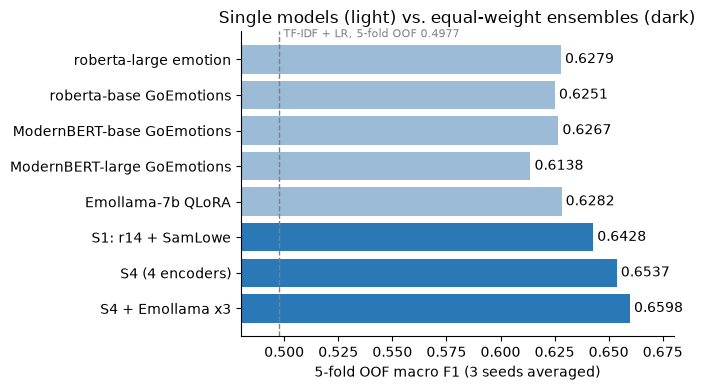

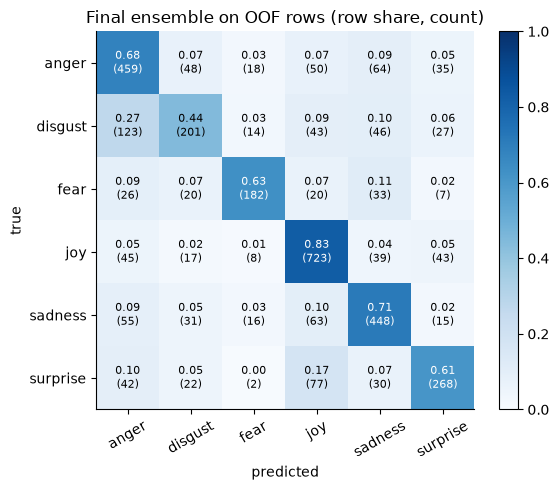

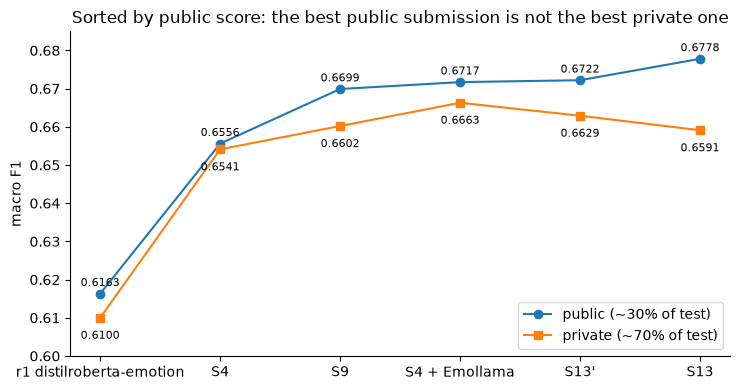

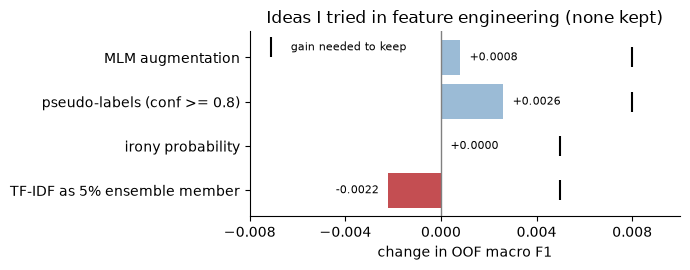

In [14]:
# ---- 3.8 figures for the report (saved to pics/report_*.png) ----
# every number below comes from the cells above, except the "ideas we tried" gains
# and the S13 row, which come from the experiment log (same source as cell 3.7).
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
PICS = Path("pics")

# (1) single models vs. ensembles: oof macro f1 from cells 3.3 and 3.4
single = {k.split(" ", 1)[1]: macro_f1(v) for k, v in oof.items()}
ens = {"S1: r14 + SamLowe": macro_f1(np.mean([oof[k] for k in encoders[:2]], 0)),
       "S4 (4 encoders)": macro_f1(np.mean([oof[k] for k in encoders], 0)),
       "S4 + Emollama x3": macro_f1(final_oof)}
names = list(single) + list(ens)
vals = list(single.values()) + list(ens.values())
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(names[::-1], vals[::-1], color=["#2a78b5"] * len(ens) + ["#9bbbd6"] * len(single))
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.axvline(0.4977, ls="--", c="gray", lw=1)
ax.text(0.4997, len(names) - 0.45, "TF-IDF + LR, 5-fold OOF 0.4977", color="gray", fontsize=8, va="bottom")
ax.set_xlim(0.48, 0.68)
ax.set_xlabel("5-fold OOF macro F1 (3 seeds averaged)")
ax.set_title("Single models (light) vs. equal-weight ensembles (dark)")
fig.tight_layout(); fig.savefig(PICS / "report_ensemble.png", dpi=150); plt.show()

# (2) confusion matrix of the final ensemble on the oof rows, row-normalized (recall per class)
cm_counts = confusion_matrix(y, final_oof.argmax(1))
cm_rate = cm_counts / cm_counts.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_rate, cmap="Blues", vmin=0, vmax=1)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{cm_rate[i, j]:.2f}\n({cm_counts[i, j]})", ha="center", va="center", fontsize=8,
                color="white" if cm_rate[i, j] > 0.5 else "black")
ax.set_xticks(range(len(LABELS)), LABELS, rotation=30); ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Final ensemble on OOF rows (row share, count)")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(PICS / "report_confusion.png", dpi=150); plt.show()

# (3) public vs. private for each submission (table 3.7 plus S13, the best public score)
lb = pd.concat([results[["submission", "public F1", "private F1"]],
                pd.DataFrame([("S13 (S9 + Emollama x2, all train)", 0.6778, 0.6591)],
                             columns=["submission", "public F1", "private F1"])], ignore_index=True)
lb = lb[lb["public F1"] > 0.6].sort_values("public F1").reset_index(drop=True)   # drop the baseline so the scale is readable
fig, ax = plt.subplots(figsize=(7.5, 4))
xs = np.arange(len(lb))
ax.plot(xs, lb["public F1"], "o-", label="public (~30% of test)")
ax.plot(xs, lb["private F1"], "s-", label="private (~70% of test)")
for x, (pu, pr) in enumerate(zip(lb["public F1"], lb["private F1"])):
    ax.text(x, pu + 0.002, f"{pu:.4f}", ha="center", fontsize=8)
    ax.text(x, pr - 0.0055, f"{pr:.4f}", ha="center", fontsize=8)
ax.set_xticks(xs, [s.split(" (")[0] for s in lb.submission])
ax.set_ylim(0.600, 0.685); ax.set_ylabel("macro F1"); ax.legend(loc="lower right")
ax.set_title("Sorted by public score: the best public submission is not the best private one")
fig.tight_layout(); fig.savefig(PICS / "report_leaderboard.png", dpi=150); plt.show()

# (4) ideas we tried that did not pass the keep rule (gain over the baseline each one was compared with)
tried = pd.DataFrame([
    ("MLM augmentation", 0.6259 - 0.6251, 0.008),
    ("pseudo-labels (conf >= 0.8)", 0.6277 - 0.6251, 0.008),
    ("irony probability", 0.0000, 0.005),
    ("TF-IDF as 5% ensemble member", -0.0022, 0.005),
], columns=["idea", "gain", "needed"])
fig, ax = plt.subplots(figsize=(7, 2.8))
yy = np.arange(len(tried))[::-1]
ax.barh(yy, tried.gain, color=["#c44e52" if g < 0 else "#9bbbd6" for g in tried.gain])
ax.scatter(tried.needed, yy, marker="|", s=200, c="black", label="gain needed to keep")
for yi, g in zip(yy, tried.gain):
    ax.text(g + (0.0004 if g >= 0 else -0.0004), yi, f"{g:+.4f}", va="center",
            ha="left" if g >= 0 else "right", fontsize=8)
ax.axvline(0, c="gray", lw=1)
ax.set_yticks(yy, tried.idea); ax.set_xlim(-0.008, 0.010); ax.set_xticks(np.arange(-0.008, 0.0101, 0.004))
ax.set_xlabel("change in OOF macro F1"); ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.set_title("Ideas I tried in feature engineering (none kept)")
fig.tight_layout(); fig.savefig(PICS / "report_tried_ideas.png", dpi=150); plt.show()


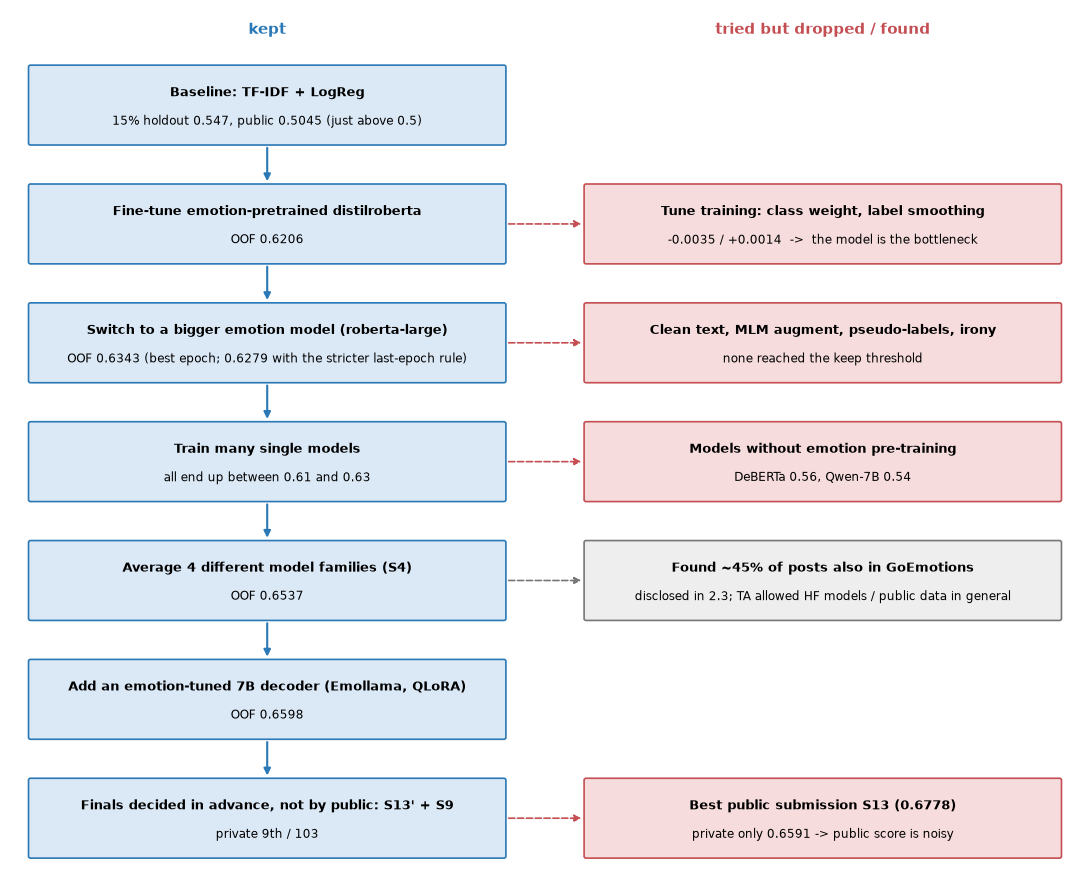

In [15]:
# ---- 3.9 which ideas we kept or dropped, for report 1.3 (pics/report_model_path.png) ----
# left column = steps we kept (OOF macro F1), right column = ideas that did not help.
# numbers come from the cells above and the experiment log.
from matplotlib.patches import FancyBboxPatch

KEPT = [
    ("Baseline: TF-IDF + LogReg", "15% holdout 0.547, public 0.5045 (just above 0.5)"),
    ("Fine-tune emotion-pretrained distilroberta", "OOF 0.6206"),
    ("Switch to a bigger emotion model (roberta-large)", "OOF 0.6343 (best epoch; 0.6279 with the stricter last-epoch rule)"),
    ("Train many single models", "all end up between 0.61 and 0.63"),
    ("Average 4 different model families (S4)", "OOF 0.6537"),
    ("Add an emotion-tuned 7B decoder (Emollama, QLoRA)", "OOF 0.6598"),
    ("Finals decided in advance, not by public: S13' + S9", "private 9th / 103"),
]
DROPPED = {  # row of KEPT it branches from -> (title, detail)
    1: ("Tune training: class weight, label smoothing", "-0.0035 / +0.0014  ->  the model is the bottleneck"),
    2: ("Clean text, MLM augment, pseudo-labels, irony", "none reached the keep threshold"),
    3: ("Models without emotion pre-training", "DeBERTa 0.56, Qwen-7B 0.54"),
    4: ("Found ~45% of posts also in GoEmotions", "disclosed in 2.3; TA allowed HF models / public data in general"),
    6: ("Best public submission S13 (0.6778)", "private only 0.6591 -> public score is noisy"),
}

def box(ax, x, y, w, h, title, detail, face, edge):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02",
                                fc=face, ec=edge, lw=1.2))
    ax.text(x, y + 0.13, title, ha="center", va="center", fontsize=9, weight="bold")
    ax.text(x, y - 0.17, detail, ha="center", va="center", fontsize=8.5)

fig, ax = plt.subplots(figsize=(11, 9))
step = 1.25
for i, (title, detail) in enumerate(KEPT):
    yy = -i * step
    box(ax, 0, yy, 4.6, 0.8, title, detail, "#dbe9f6", "#2a78b5")
    if i < len(KEPT) - 1:
        ax.annotate("", xy=(0, yy - step + 0.42), xytext=(0, yy - 0.42),
                    arrowprops=dict(arrowstyle="-|>", color="#2a78b5", lw=1.5))
for i, (title, detail) in DROPPED.items():
    yy = -i * step
    grey = i == 4                                   # a finding, not a failed idea
    box(ax, 5.4, yy, 4.6, 0.8, title, detail,
        "#eeeeee" if grey else "#f6dcdc", "#777777" if grey else "#c44e52")
    ax.annotate("", xy=(3.08, yy), xytext=(2.32, yy),
                arrowprops=dict(arrowstyle="-|>", color="#777777" if grey else "#c44e52", lw=1.2, ls="--"))
ax.text(0, 0.75, "kept", ha="center", fontsize=11, color="#2a78b5", weight="bold")
ax.text(5.4, 0.75, "tried but dropped / found", ha="center", fontsize=11, color="#c44e52", weight="bold")
ax.set_xlim(-2.5, 7.9); ax.set_ylim(-len(KEPT) * step + 0.6, 1.0)
ax.axis("off")
fig.tight_layout(); fig.savefig(PICS / "report_model_path.png", dpi=150); plt.show()


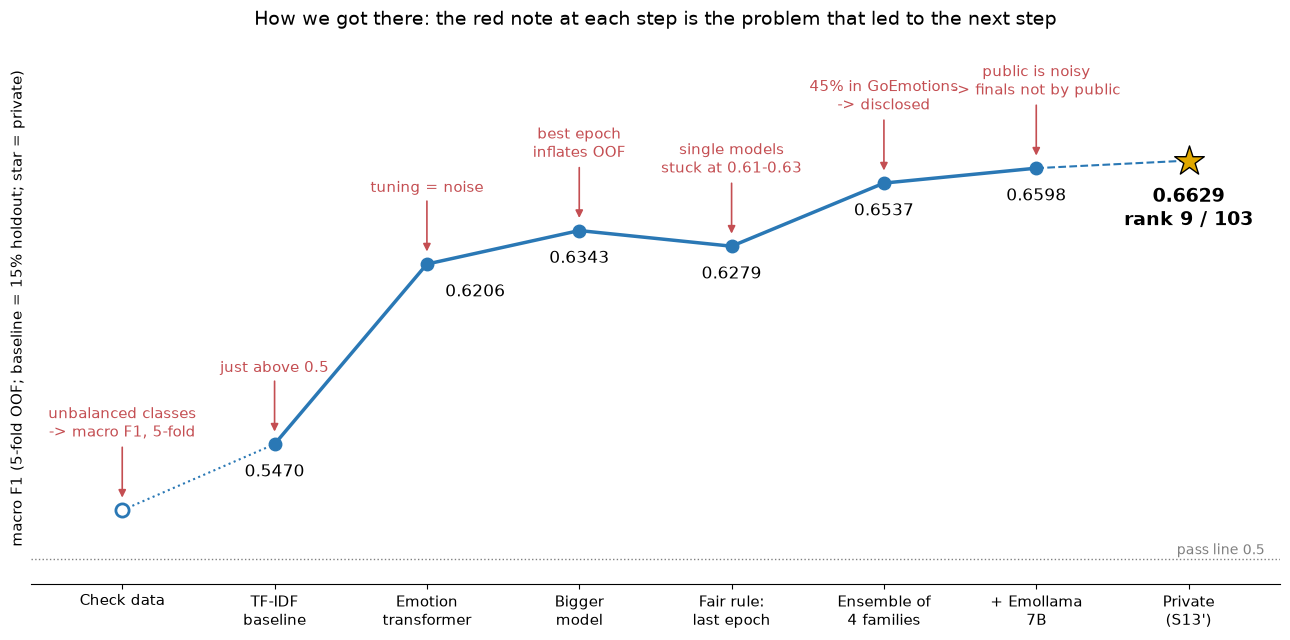

In [16]:
# ---- 3.10 the whole process as a score staircase, for the start of the report (pics/report_flow.png) ----
# x = steps in the order we did them, y = 5-fold OOF macro F1 (baseline = 15% holdout, the star is the private score).
# each red note points at the step where we found that problem; it is the reason for the next step.
# numbers come from the cells above and the experiment log.
STEPS = [  # (step, score, problem found at this step)
    ("Check data", 0.52, "unbalanced classes\n-> macro F1, 5-fold"),   # no model yet: drawn as a hollow marker
    ("TF-IDF\nbaseline", 0.547, "just above 0.5"),
    ("Emotion\ntransformer", 0.6206, "tuning = noise"),
    ("Bigger\nmodel", 0.6343, "best epoch\ninflates OOF"),
    ("Fair rule:\nlast epoch", 0.6279, "single models\nstuck at 0.61-0.63"),
    ("Ensemble of\n4 families", 0.6537, "45% in GoEmotions\n-> disclosed"),
    ("+ Emollama\n7B", 0.6598, "public is noisy\n-> finals not by public"),
]
FINAL = ("Private\n(S13')", 0.6629)
RED = "#c44e52"

xs = np.arange(len(STEPS))
ys = [s for _, s, _ in STEPS]
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.plot(xs[1:], ys[1:], "o-", color="#2a78b5", lw=2.5, ms=9, zorder=3)
ax.plot(xs[:2], ys[:2], ":", color="#2a78b5", lw=1.5)
ax.scatter([0], [ys[0]], s=90, facecolor="white", edgecolor="#2a78b5", lw=2, zorder=3)
ax.plot([xs[-1], len(STEPS)], [ys[-1], FINAL[1]], "--", color="#2a78b5", lw=1.5)
ax.scatter([len(STEPS)], [FINAL[1]], marker="*", s=500, color="#e0a800", ec="black", zorder=4)
for x, s in zip(xs[1:], ys[1:]):                     # score under each point
    ax.text(x + (0.12 if x == 2 else 0), s - 0.008, f"{s:.4f}", ha="left" if x == 2 else "center",
            va="top", fontsize=12)
ax.text(len(STEPS), FINAL[1] - 0.010, f"{FINAL[1]:.4f}\nrank 9 / 103", ha="center", va="top",
        fontsize=14, weight="bold")
for x, (_, s, problem) in enumerate(STEPS):          # red note just above its own point, with a short arrow
    ax.annotate(problem, xy=(x, s + 0.004), xytext=(x, s + 0.028), ha="center", va="bottom",
                fontsize=11, color=RED, arrowprops=dict(arrowstyle="-|>", color=RED, lw=1.2))
ax.axhline(0.5, color="gray", ls=":", lw=1); ax.text(len(STEPS) + 0.5, 0.502, "pass line 0.5",
                                                     color="gray", fontsize=10, ha="right")
ax.set_xticks(range(len(STEPS) + 1), [s for s, _, _ in STEPS] + [FINAL[0]], fontsize=11)
ax.set_yticks([]); ax.set_ylabel("macro F1 (5-fold OOF; baseline = 15% holdout; star = private)", fontsize=11)
ax.set_xlim(-0.6, len(STEPS) + 0.6); ax.set_ylim(0.49, 0.715)
ax.spines["left"].set_visible(False)
ax.set_title("How we got there: the red note at each step is the problem that led to the next step",
             fontsize=14)
fig.tight_layout(); fig.savefig(PICS / "report_flow.png", dpi=150); plt.show()


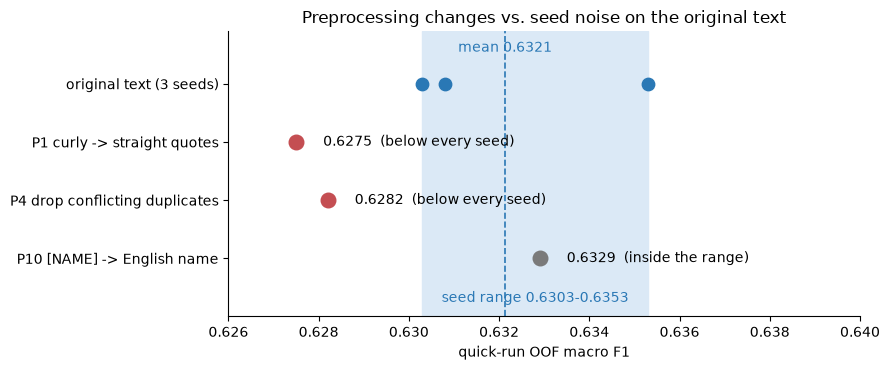

In [17]:
# ---- 3.11 preprocessing experiments vs. the seed range of the original text (pics/report_preprocessing.png) ----
# quick setup (3 folds, max_len 64, 3 epochs), scores from the experiment log.
BASE_SEEDS = {"seed 42": 0.6303, "seed 7": 0.6353, "seed 123": 0.6308}   # original text
PREP = [("P1 curly -> straight quotes", 0.6275), ("P4 drop conflicting duplicates", 0.6282),
        ("P10 [NAME] -> English name", 0.6329)]
lo, hi = min(BASE_SEEDS.values()), max(BASE_SEEDS.values())
mean = np.mean(list(BASE_SEEDS.values()))

fig, ax = plt.subplots(figsize=(9, 3.8))
rows = ["original text (3 seeds)"] + [p for p, _ in PREP]
yy = np.arange(len(rows))[::-1]
ax.axvspan(lo, hi, color="#dbe9f6", zorder=0)
ax.axvline(mean, color="#2a78b5", ls="--", lw=1.2)
ax.text(mean, yy[0] + 0.55, f"mean {mean:.4f}", ha="center", color="#2a78b5", fontsize=10)
ax.text((lo + hi) / 2, yy[-1] - 0.75, f"seed range {lo:.4f}-{hi:.4f}", ha="center", color="#2a78b5", fontsize=10)
ax.scatter(list(BASE_SEEDS.values()), [yy[0]] * 3, s=80, color="#2a78b5", zorder=3)
for (name, s), y_ in zip(PREP, yy[1:]):
    inside = lo <= s <= hi
    ax.scatter([s], [y_], s=110, color="#7a7a7a" if inside else "#c44e52", zorder=3)
    ax.text(s + 0.0006, y_, f"{s:.4f}" + ("  (inside the range)" if inside else "  (below every seed)"),
            va="center", fontsize=10)
ax.set_yticks(yy, rows, fontsize=10)
ax.set_xlim(0.626, 0.640); ax.set_ylim(yy[-1] - 1.0, yy[0] + 0.9)
ax.set_xlabel("quick-run OOF macro F1")
ax.set_title("Preprocessing changes vs. seed noise on the original text", fontsize=12)
fig.tight_layout(); fig.savefig(PICS / "report_preprocessing.png", dpi=150); plt.show()
